## Forest Vegetation Analysis
Initial analysis for Remote Sensing term project.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Load the datasets
forest_df = pd.read_csv('../forest.csv')
combined_df = pd.read_csv('../combined_results.csv')

print("Forest data shape:", forest_df.shape)
print("\nForest data columns:", forest_df.columns.tolist())
print("\nForest data preview:")
print(forest_df.head())

print("\n" + "="*60 + "\n")

print("Combined results shape:", combined_df.shape)
print("\nCombined results columns:", combined_df.columns.tolist())
print("\nCombined results preview:")
print(combined_df[['site', 'rmse_s01011010_ghelaps']].head())

Forest data shape: (10, 3)

Forest data columns: ['Site', 'Sentinel Forest', 'NLCD Forest']

Forest data preview:
                Site  Sentinel Forest  NLCD Forest
0          Elk Cabin             0.51         0.91
1      Gallegos Peak              NaN         0.99
2        Garita Peak             0.84         0.90
3           Quemazon             0.62         0.35
4  Rio Santa Barbara             0.78         0.98


Combined results shape: (784, 20)

Combined results columns: ['site', 'latitude', 'longitude', 'output_years', 'bias_s00000000_ghec', 'rmse_s00000000_ghec', 'mean_snotel_swe', 'var_snotel_swe', 'bias_s01011010_gbc', 'rmse_s01011010_gbc', 'bias_s01011010_ghec', 'rmse_s01011010_ghec', 'bias_s01011010_ghelaps', 'rmse_s01011010_ghelaps', 'drmse_s01011010_gbc', 'drmse_s01011010_ghec', 'drmse_s01011010_ghelaps', 'dbias_s01011010_gbc', 'dbias_s01011010_ghec', 'dbias_s01011010_ghelaps']

Combined results preview:
               site  rmse_s01011010_ghelaps
0  Forestdale Creek    

In [6]:
# Merge the datasets on site name
# The forest.csv uses 'Site' and combined_results.csv uses 'site'
merged_df = pd.merge(
    forest_df, 
    combined_df, 
    left_on='Site', 
    right_on='site', 
    how='inner'
)

# Normalize RMSE by mean SNOTEL SWE
merged_df['nrmse'] = merged_df['rmse_s01011010_gbc'] / merged_df['mean_snotel_swe']

print(f"Number of matching sites: {len(merged_df)}")
print("\nMerged data preview:")
print(merged_df[['Site', 'Sentinel Forest', 'NLCD Forest', 'rmse_s01011010_gbc', 'mean_snotel_swe', 'nrmse']].head())
# Check for any sites in forest.csv that didn't match
unmatched_sites = forest_df[~forest_df['Site'].isin(merged_df['Site'])]
if len(unmatched_sites) > 0:
    print(f"\nWarning: {len(unmatched_sites)} sites from forest.csv did not match:")
    print(unmatched_sites['Site'].tolist())

Number of matching sites: 10

Merged data preview:
                Site  Sentinel Forest  NLCD Forest  rmse_s01011010_gbc  \
0          Elk Cabin             0.51         0.91                15.5   
1      Gallegos Peak              NaN         0.99                34.1   
2        Garita Peak             0.84         0.90                14.9   
3           Quemazon             0.62         0.35                31.5   
4  Rio Santa Barbara             0.78         0.98                56.2   

   mean_snotel_swe     nrmse  
0             17.8  0.870787  
1             68.8  0.495640  
2             42.0  0.354762  
3             51.0  0.617647  
4            102.9  0.546161  


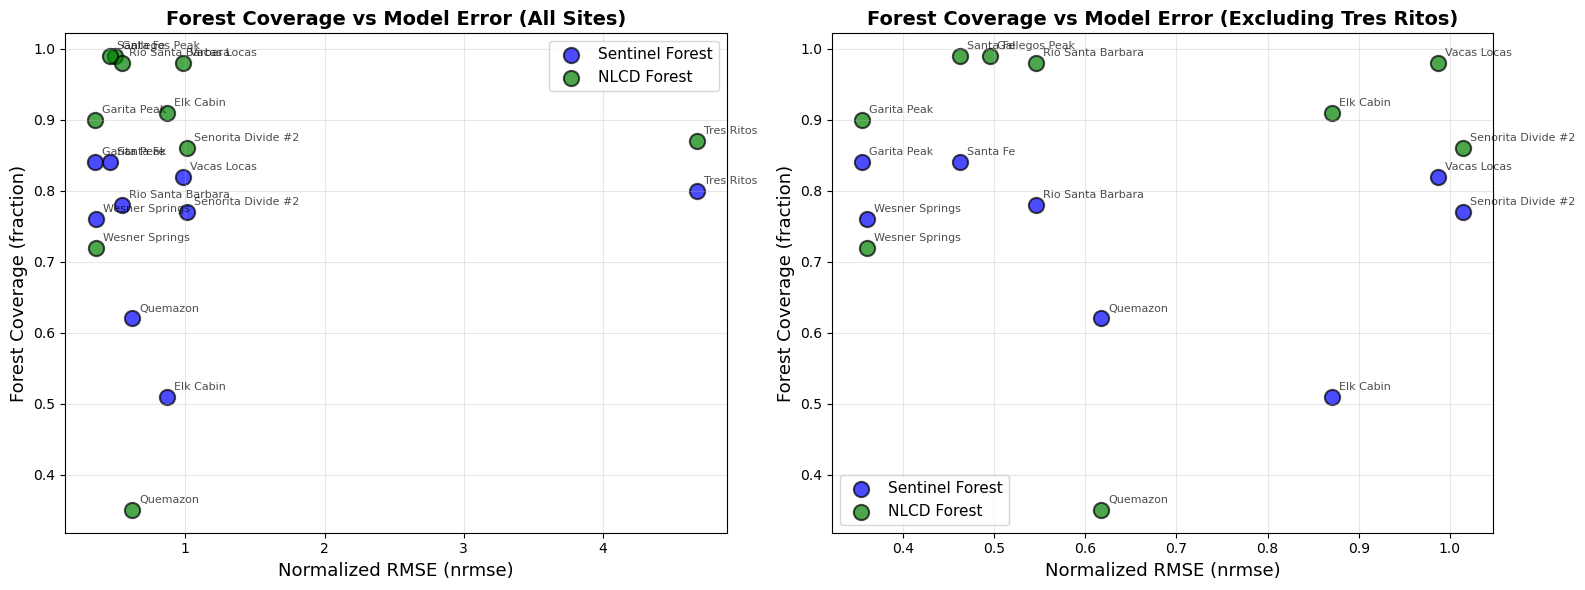


All data - Sentinel Forest data points: 9
All data - NLCD Forest data points: 10

Excluding Tres Ritos - Sentinel Forest data points: 8
Excluding Tres Ritos - NLCD Forest data points: 9


In [8]:
# Create side-by-side subplots: one with all data, one without Tres Ritos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Filter data without Tres Ritos
merged_no_outlier = merged_df[merged_df['Site'] != 'Tres Ritos']
sentinel_no_outlier = merged_no_outlier.dropna(subset=['Sentinel Forest'])

# Plot 1: All data including Tres Ritos
ax1 = axes[0]
sentinel_data = merged_df.dropna(subset=['Sentinel Forest'])
ax1.scatter(sentinel_data['nrmse'],
           sentinel_data['Sentinel Forest'], 
           alpha=0.7, s=120, edgecolors='black', linewidth=1.5,
           color='blue', label='Sentinel Forest')

for idx, row in sentinel_data.iterrows():
    ax1.annotate(row['Site'], 
                (row['nrmse'], row['Sentinel Forest']),
                fontsize=8, alpha=0.7, xytext=(5, 5), 
                textcoords='offset points')

ax1.scatter(merged_df['nrmse'],
           merged_df['NLCD Forest'], 
           alpha=0.7, s=120, edgecolors='black', linewidth=1.5,
           color='green', label='NLCD Forest')

for idx, row in merged_df.iterrows():
    ax1.annotate(row['Site'], 
                (row['nrmse'], row['NLCD Forest']),
                fontsize=8, alpha=0.7, xytext=(5, 5), 
                textcoords='offset points')

ax1.set_xlabel('Normalized RMSE (nrmse)', fontsize=13)
ax1.set_ylabel('Forest Coverage (fraction)', fontsize=13)
ax1.set_title('Forest Coverage vs Model Error (All Sites)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=11, loc='best')

# Plot 2: Data without Tres Ritos
ax2 = axes[1]
ax2.scatter(sentinel_no_outlier['nrmse'],
           sentinel_no_outlier['Sentinel Forest'], 
           alpha=0.7, s=120, edgecolors='black', linewidth=1.5,
           color='blue', label='Sentinel Forest')

for idx, row in sentinel_no_outlier.iterrows():
    ax2.annotate(row['Site'], 
                (row['nrmse'], row['Sentinel Forest']),
                fontsize=8, alpha=0.7, xytext=(5, 5), 
                textcoords='offset points')

ax2.scatter(merged_no_outlier['nrmse'],
           merged_no_outlier['NLCD Forest'], 
           alpha=0.7, s=120, edgecolors='black', linewidth=1.5,
           color='green', label='NLCD Forest')

for idx, row in merged_no_outlier.iterrows():
    ax2.annotate(row['Site'], 
                (row['nrmse'], row['NLCD Forest']),
                fontsize=8, alpha=0.7, xytext=(5, 5), 
                textcoords='offset points')

ax2.set_xlabel('Normalized RMSE (nrmse)', fontsize=13)
ax2.set_ylabel('Forest Coverage (fraction)', fontsize=13)
ax2.set_title('Forest Coverage vs Model Error (Excluding Tres Ritos)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=11, loc='best')

plt.tight_layout()
plt.show()

print(f"\nAll data - Sentinel Forest data points: {len(sentinel_data)}")
print(f"All data - NLCD Forest data points: {len(merged_df)}")
print(f"\nExcluding Tres Ritos - Sentinel Forest data points: {len(sentinel_no_outlier)}")
print(f"Excluding Tres Ritos - NLCD Forest data points: {len(merged_no_outlier)}")